# M5. 우리 동네 낮 · 밤 인구

서울 행정동 생활인구 한 달치(30만 행)를 pandas 로 정제하고 DuckDB 의 PIVOT · 비율 · 순위 윈도 함수로 「낮에 붐비는 동네(출근지)」와 「밤에 붐비는 동네(주거지)」를 가른 뒤, 자치구 단위로 올려 봅니다.

- 단계: 기초 미니 프로젝트 · 정형 · 예상 반나절~하루
- 실행 환경: Google Colab(브라우저만 있으면 됩니다)
- 데이터: 서울 열린데이터광장 — 행정동 단위 서울 생활인구(내국인)(OA-14991) 2026년 6월분, 공공누리 1유형(출처표시)
- 데이터: 공공데이터포털 — 소상공인시장진흥공단_상가(상권)정보(15083033) 2026-06-30 기준 서울 음식 업종 파일(행정동 · 자치구 이름표로만 사용), 이용허락 제한 없음

셀을 위에서부터 차례로 실행하세요. 각 단계 끝의 **확인 포인트** 숫자가 같게 나오면 다음 단계로 갑니다.
따라하기를 한 번 끝냈다면 같은 내용의 [빈칸 노트북](https://colab.research.google.com/github/aebonlee/materials/blob/main/data-eng/projects/M5/M5_blank.ipynb)으로 다시 쳐 보세요.

서울시는 통신 데이터로 「그 시각 그 동네에 있던 사람 수」를 추정해 **생활인구**라는 이름으로 공개합니다. 주민등록 인구와 달리, 낮에 회사에 와 있는 사람도 그 동네 인구로 셉니다.
그래서 같은 동네라도 낮과 밤의 숫자가 크게 다릅니다. 이 프로젝트에서는 그 차이로 **「낮에 붐비는 동네(출근지)」와 「밤에 붐비는 동네(주거지)」**를 숫자로 가릅니다.

흐름은 1~3주차에 배운 그대로입니다.

```text
생활인구 CSV(행 끝 쉼표 · BOM) → pandas 읽기 · 정제(날짜 · 평일 · 이름표) → DuckDB PIVOT · 비율 · 순위 → 자치구로 올리기 → Parquet · 그래프
```

다 끝내면 다음 세 가지를 말할 수 있습니다.

- 서울에서 낮/밤 인구 비율이 가장 큰 동네와 가장 작은 동네, 그리고 그 비율로 나눈 세 무리의 크기
- 자치구로 올렸을 때 순위가 어떻게 되는지, 「동 비율의 평균」을 쓰면 왜 틀리는지
- 6월 3일(수)을 평일에서 빼야 하는 이유

## 1단계 · 준비 — 라이브러리와 데이터

Colab 에는 pandas 와 DuckDB 가 이미 깔려 있습니다. 데이터는 공개 자료실에서 두 파일을 받습니다.

- **생활인구** — 서울 열린데이터광장 「행정동 단위 서울 생활인구(내국인)」 2026년 6월 파일입니다. 원본의 32개 열 중 앞 4개(날짜 · 시간대 · 행정동코드 · 총생활인구수)만 남겼고, 행 모양(UTF-8 BOM, 데이터 행 끝의 쉼표)은 원본 그대로 두었습니다. 공공누리 1유형(출처표시)입니다.
- **행정동 이름표** — 생활인구 파일에는 행정동 **코드**만 있고 이름이 없습니다. 이름은 공공데이터포털 「소상공인시장진흥공단_상가(상권)정보」 2026-06-30 기준 서울 음식 업종 파일(P3 에서 쓴 것과 같은 파일)에서 코드와 이름의 짝만 뽑아 씁니다. 이용허락 범위는 「제한 없음」입니다.

In [ ]:
import os, gzip, shutil, urllib.request
import pandas as pd
import duckdb

DATA = "https://raw.githubusercontent.com/aebonlee/materials/main/data-eng/projects/data/"

def fetch(name):
    """프로젝트 데이터를 ./data 폴더에 한 번만 받아 둡니다."""
    os.makedirs("data", exist_ok=True)
    dst = os.path.join("data", name)
    if not os.path.exists(dst):
        local = os.environ.get("DE_DATA_LOCAL")          # 오프라인 실습용 — 자료 폴더가 내 컴퓨터에 있을 때
        if local:
            shutil.copy(os.path.join(local, name), dst)
        else:
            urllib.request.urlretrieve(DATA + name, dst)
    return dst

pop_path = fetch("seoul_living_pop_dong_202606.csv.gz")
store_path = fetch("seoul_store_food_202606.csv.gz")
for p in (pop_path, store_path):
    print(p, round(os.path.getsize(p) / 1e6, 1), "MB")

data/seoul_living_pop_dong_202606.csv.gz 2.6 MB
data/seoul_store_food_202606.csv.gz 5.8 MB


> **확인 포인트** — `seoul_living_pop_dong_202606.csv.gz 2.6 MB` · `seoul_store_food_202606.csv.gz 5.8 MB`.

> **Aebon's Tip** — 서울 생활인구는 2026년 7월분을 끝으로 행정동 단위 생산이 끝나고 국가표준격자(250m) 단위로 바뀐다고 데이터셋 화면에 안내되어 있습니다.
> 이 프로젝트의 코드는 「장소 코드 · 시각 · 인구」 세 칸이면 그대로 돌아가므로, 격자 자료에도 열 이름만 바꿔 쓸 수 있습니다.

## 2단계 · 읽기 — 행 끝 쉼표와 BOM

먼저 파일의 첫 두 줄을 글자 그대로 봅니다. 공공 CSV 는 읽기 전에 눈으로 한 번 보는 것이 가장 빠른 진단입니다.

In [ ]:
with gzip.open(pop_path, "rt", encoding="utf-8") as f:
    head = [f.readline() for _ in range(2)]
for line in head:
    print(repr(line))

'\ufeff"기준일ID","시간대구분","행정동코드","총생활인구수"\n'
'"20260601","00","11740685","61126.7274",\n'


두 가지가 보입니다. 첫 줄 맨 앞의 `﻿` 는 **BOM**(이 파일이 UTF-8 이라고 알리는 표식)이고, 데이터 줄은 끝에 쉼표가 하나 더 붙어 **머리줄 4칸 · 데이터 5칸**입니다.

In [ ]:
assert head[0].startswith("﻿") and head[1].rstrip("\n").endswith(",")
assert head[0].count(",") == 3 and head[1].count(",") == 4

DuckDB 의 `read_csv` 는 파일 모양을 스스로 알아내는(sniffing) 기능이 있습니다(3주차 14장). 이 파일에 그대로 써 봅니다.

In [ ]:
try:
    duckdb.sql(f"SELECT * FROM read_csv('{pop_path}') LIMIT 3").df()
except duckdb.Error as e:
    print(type(e).__name__, "—", str(e).splitlines()[0][:90])

InvalidInputException — Invalid Input Error: Error when sniffing file "data/seoul_living_pop_dong_202606.csv.gz".


칸 수가 줄마다 달라서 모양을 알아내지 못하고 멈춥니다. 이번에는 pandas 로 읽습니다. pandas 는 BOM 을 알아서 지우지만, 행 끝 쉼표에는 **조용히** 속습니다 — 칸이 하나 많으면 맨 앞 칸(날짜)을 행 번호로 써 버립니다.

In [ ]:
bad = pd.read_csv(pop_path, dtype=str)
print(bad.head(2))
print("총생활인구수 빈 값:", bad["총생활인구수"].isna().sum(), "/", len(bad))

         기준일ID     시간대구분       행정동코드 총생활인구수
20260601    00  11740685  61126.7274    NaN
20260601    00  11740700  26768.0465    NaN
총생활인구수 빈 값: 305280 / 305280


`index_col=False` 를 주면 「맨 앞 칸을 행 번호로 쓰지 말라」는 뜻이 되어, 남는 마지막 빈칸을 버리고 바르게 읽습니다(P3 2단계와 같은 함정입니다).

In [ ]:
raw = pd.read_csv(pop_path, dtype=str, index_col=False)
print(raw.shape, raw.columns.tolist())
print("날짜:", raw["기준일ID"].min(), "~", raw["기준일ID"].max(), "· 행정동:", raw["행정동코드"].nunique())

(305280, 4) ['기준일ID', '시간대구분', '행정동코드', '총생활인구수']
날짜: 20260601 ~ 20260630 · 행정동: 424


> **확인 포인트** — `(305280, 4)` — 30일 × 24시간 × 행정동 424곳입니다. 첫 열 이름에 BOM 이 붙지 않은 `기준일ID` 로 읽혔습니다.

In [ ]:
assert raw.shape == (305280, 4) and raw["행정동코드"].nunique() == 424
assert raw.columns[0] == "기준일ID" and bad["총생활인구수"].isna().all()

> **Aebon's Tip** — DuckDB 로 바로 읽고 싶으면 `read_csv(..., null_padding=true)` 를 주세요. 모자란 칸을 빈 값으로 채워 읽어서 행 끝 쉼표를 견딥니다.
> 반대로 내 프로그램에서 `open()` 으로 직접 읽을 때는 `encoding="utf-8-sig"` 를 써야 첫 열 이름에 `﻿` 가 붙지 않습니다.

## 3단계 · 정제 — 형 바꾸기, 평일 고르기, 이름표 붙이기

열 이름을 영어로 바꾸고 날짜 · 시각 · 인구를 알맞은 형으로 바꿉니다. 행정동 코드는 앞자리가 의미 있는 코드라 글자로 둡니다 — **앞 5자리가 자치구 코드**입니다.

In [ ]:
pop = pd.DataFrame({
    "base_date": pd.to_datetime(raw["기준일ID"], format="%Y%m%d"),
    "hour": raw["시간대구분"].astype(int),
    "dong_cd": raw["행정동코드"],
    "pop": raw["총생활인구수"].astype(float),
})
pop["gu_cd"] = pop["dong_cd"].str[:5]
print(pop.dtypes.to_dict())
print("자치구:", pop["gu_cd"].nunique(), "· 빈 값:", pop.isna().sum().sum())

{'base_date': dtype('<M8[ns]'), 'hour': dtype('int64'), 'dong_cd': dtype('O'), 'pop': dtype('float64'), 'gu_cd': dtype('O')}
자치구: 25 · 빈 값: 0


「낮 인구」는 **평일 낮**으로 잽니다. 주말에는 회사가 쉬어 출근지가 비기 때문입니다. 요일만으로 평일을 고르면 될까요? 평일(월~금)마다 오후 2시 서울 전체 인구를 세어 봅니다.

In [ ]:
weekday_14 = duckdb.sql("""
    SELECT base_date, dayname(base_date) AS dow, round(sum(pop)) AS seoul_pop
    FROM pop
    WHERE isodow(base_date) BETWEEN 1 AND 5 AND hour = 14
    GROUP BY base_date
    ORDER BY seoul_pop
    LIMIT 3
""").df()
weekday_14

,base_date,dow,seoul_pop
0,2026-06-03,Wednesday,10013461.0
1,2026-06-26,Friday,10611540.0
2,2026-06-19,Friday,10629266.0


> **확인 포인트** — 가장 적은 날은 **2026-06-03(수) 10,013,461명**으로, 다음 날들(1,061만 명대)보다 60만 명 넘게 적습니다.
> 6월 3일은 제9회 전국동시지방선거일로 법정 공휴일이었습니다. 요일로는 평일이지만 사람들의 움직임은 휴일입니다.

In [ ]:
assert str(weekday_14.iloc[0]["base_date"])[:10] == "2026-06-03" and weekday_14.iloc[0]["seoul_pop"] == 10013461

공휴일을 뺀 「일하는 날」 표시를 만듭니다.

In [ ]:
HOLIDAYS = [pd.Timestamp("2026-06-03")]                 # 6/6 현충일은 토요일이라 이미 주말입니다
pop["workday"] = (pop["base_date"].dt.dayofweek < 5) & ~pop["base_date"].isin(HOLIDAYS)
n_work = pop.drop_duplicates("base_date")["workday"].sum()
print("일하는 날:", n_work, "일")
assert n_work == 21

일하는 날: 21 일


이제 이름표입니다. 상가정보에서 행정동 코드와 이름, 자치구 코드와 이름의 짝을 겹치지 않게 뽑습니다.

In [ ]:
store = pd.read_csv(store_path, dtype=str, usecols=["시군구코드", "시군구명", "행정동코드", "행정동명"])
dong = store[["행정동코드", "행정동명"]].drop_duplicates().rename(columns={"행정동코드": "dong_cd", "행정동명": "dong_nm"})
gu = store[["시군구코드", "시군구명"]].drop_duplicates().rename(columns={"시군구코드": "gu_cd", "시군구명": "gu_nm"})
print("행정동 이름:", len(dong), "· 자치구 이름:", len(gu))

no_name = sorted(set(pop["dong_cd"]) - set(dong["dong_cd"]))
no_gu = set(pop["gu_cd"]) - set(gu["gu_cd"])
print("이름이 없는 생활인구 행정동:", len(no_name), no_name[:4], "… · 이름이 없는 자치구:", len(no_gu))

행정동 이름: 427 · 자치구 이름: 25
이름이 없는 생활인구 행정동: 9 ['11230536', '11305590', '11305600', '11305606'] … · 이름이 없는 자치구: 0


> **확인 포인트** — 행정동 이름 427개 · 자치구 이름 25개. 생활인구의 행정동 가운데 **9개**는 이름표에 없고, 자치구는 25개 모두 있습니다.
> P3 5단계에서 본 그 9개입니다 — 행정동이 나뉘거나 합쳐지며 코드가 바뀌었는데, 두 기관이 코드표를 바꾼 시점이 다릅니다.

In [ ]:
assert len(dong) == 427 and len(gu) == 25 and len(no_name) == 9 and not no_gu
assert dong["dong_cd"].is_unique

이름이 없다고 이 9개 동의 인구를 버리면, 6단계에서 강북구 인구가 통째로 줄어듭니다. 그래서 **인구는 모두 두고, 이름만 비워** 둡니다(LEFT JOIN). 자치구는 코드 앞 5자리로 붙이니 9개 동도 자기 구에 들어갑니다.

## 4단계 · DuckDB — 동네마다 낮 · 밤 인구와 비율

시간대를 둘로 나눕니다.

- **낮** = 일하는 날의 10~17시 — 출근한 사람이 회사에 있는 시간
- **밤** = 30일 모두의 0~5시 — 대부분 집에서 자는 시간

DuckDB 의 `PIVOT` 은 한 열의 값(여기서는 `period` 의 `day_pop` · `night_pop`)을 열 이름으로 펼칩니다. `GROUP BY` 와 `FILTER` 로도 같은 표를 만들 수 있지만, 펼칠 값이 많을 때는 PIVOT 이 짧습니다.

In [ ]:
dn = duckdb.sql("""
    PIVOT (
        SELECT dong_cd, pop,
               CASE WHEN workday AND hour BETWEEN 10 AND 17 THEN 'day_pop'
                    WHEN hour BETWEEN 0 AND 5 THEN 'night_pop' END AS period
        FROM pop
    )
    ON period IN ('day_pop', 'night_pop')
    USING avg(pop)
    GROUP BY dong_cd
""").df()
print(dn.shape)
dn.sort_values("dong_cd").head(3)

(424, 3)


,dong_cd,day_pop,night_pop
381,11110515,21375.283639,14597.733009
38,11110530,42630.307011,10762.472804
64,11110540,10929.215451,4267.231540


> **확인 포인트** — `(424, 3)` — 동마다 한 줄, 낮 · 밤 평균 인구 두 칸입니다. `period` 가 NULL 인 시각(아침 6~9시 · 저녁 등)은 `IN` 목록에 없어 버려집니다.

In [ ]:
assert dn.shape == (424, 3) and dn.isna().sum().sum() == 0

비율(낮 ÷ 밤)을 내고, 이름표를 붙이고, 순위를 매깁니다. 순위는 윈도 함수 `rank()` 로 매깁니다(2주차 8장). 같은 값이면 같은 등수를 줍니다.

In [ ]:
ranked = duckdb.sql("""
    SELECT d.dong_cd, coalesce(n.dong_nm, '(코드만 ' || d.dong_cd || ')') AS dong_nm, g.gu_nm,
           round(d.day_pop) AS day_pop, round(d.night_pop) AS night_pop,
           round(d.day_pop / d.night_pop, 2) AS ratio,
           rank() OVER (ORDER BY d.day_pop / d.night_pop DESC) AS rk
    FROM dn d
    LEFT JOIN dong n USING (dong_cd)
    JOIN gu g ON g.gu_cd = left(d.dong_cd, 5)
    ORDER BY rk
""").df()
print(len(ranked))
ranked.head(6)

424


,dong_cd,dong_nm,gu_nm,day_pop,night_pop,ratio,rk
0,11140520,소공동,중구,60005.0,5591.0,10.73,1
1,11140540,회현동,중구,60851.0,7681.0,7.92,2
2,11140550,명동,중구,82302.0,10474.0,7.86,3
3,11140605,을지로동,중구,32702.0,6173.0,5.30,4
4,11110615,종로1.2.3.4가동,종로구,114394.0,24081.0,4.75,5
5,11680580,삼성1동,강남구,76647.0,18025.0,4.25,6


> **확인 포인트** — 1위는 **중구 소공동 10.73배**(낮 60,005명 · 밤 5,591명), 이어서 회현동 7.92 · 명동 7.86 입니다 — 밤에는 비고 낮에 붐비는 도심 업무지입니다.
> 강남구 삼성1동(4.25) · 영등포구 여의동(3.48)도 10위 안에 있습니다.

In [ ]:
top = ranked.iloc[0]
assert len(ranked) == 424 and top["dong_nm"] == "소공동" and top["ratio"] == 10.73 and top["day_pop"] == 60005
assert ranked.iloc[1]["dong_nm"] == "회현동" and ranked.iloc[2]["dong_nm"] == "명동"

In [ ]:
ranked.tail(4)

,dong_cd,dong_nm,gu_nm,day_pop,night_pop,ratio,rk
420,11620665,서림동,관악구,12371.0,21688.0,0.57,421
421,11710540,마천1동,송파구,8015.0,14079.0,0.57,422
422,11290590,돈암2동,성북구,10031.0,17739.0,0.57,423
423,11110690,창신3동,종로구,3464.0,6598.0,0.52,424


> **확인 포인트** — 꼴찌는 **종로구 창신3동 0.52배**입니다. 낮에는 밤 인구의 절반만 남는, 출근하러 나가는 주택가입니다.
> 비율이 가장 작은 동네 넷은 모두 0.6 아래입니다(성북구 돈암2동 · 송파구 마천1동 · 관악구 서림동 0.57).

In [ ]:
assert ranked.iloc[-1]["dong_nm"] == "창신3동" and ranked.iloc[-1]["ratio"] == 0.52

**공휴일을 빼지 않았다면** 어떻게 됐을까요? 요일로만 평일을 고른 판으로 소공동 낮 인구를 다시 내 봅니다.

In [ ]:
naive = duckdb.sql("""
    SELECT round(avg(pop)) AS day_pop FROM pop
    WHERE dong_cd = '11140520' AND isodow(base_date) <= 5 AND hour BETWEEN 10 AND 17
""").fetchall()[0][0]
print("요일만으로:", naive, "· 공휴일을 뺀 판:", top["day_pop"])
assert naive == 58223 and naive < top["day_pop"]

요일만으로: 58223.0 · 공휴일을 뺀 판: 60005.0


> **확인 포인트** — 요일로만 고르면 소공동 낮 인구가 **58,223명**으로 1,782명 줄어듭니다. 하루가 섞였을 뿐인데 업무지일수록 크게 흔들립니다.

이제 비율로 동네를 세 무리로 나눕니다. 경계 1.5 와 0.8 은 「낮에 1.5배 넘게 붐빈다」 · 「낮에 5분의 1 넘게 빈다」는 뜻으로 정한 값이라, 보고서에 기준과 함께 적어야 합니다.

In [ ]:
kinds = duckdb.sql("""
    SELECT CASE WHEN ratio >= 1.5 THEN 'day (office)'
                WHEN ratio < 0.8 THEN 'night (home)'
                ELSE 'mixed' END AS kind,
           count(*) AS dongs
    FROM ranked
    GROUP BY kind
    ORDER BY dongs DESC
""").df()
kinds

,kind,dongs
0,mixed,223
1,night (home),146
2,day (office),55


> **확인 포인트** — 섞인 동네 **223곳**, 주거지 **146곳**, 출근지 **55곳**입니다. 서울 행정동 셋 중 하나는 낮에 사람이 빠져나가는 동네입니다.

In [ ]:
assert dict(zip(kinds["kind"], kinds["dongs"])) == {"mixed": 223, "night (home)": 146, "day (office)": 55}

## 5단계 · 자치구로 올리기 — 비율의 평균은 비율이 아니다

자치구의 낮/밤 비율은 **동 인구를 먼저 더한 뒤** 나눕니다. 먼저 틀린 방법부터 봅니다 — 동 비율을 그냥 평균 내기입니다.

In [ ]:
wrong = duckdb.sql("""
    SELECT gu_nm, round(avg(day_pop / night_pop), 2) AS mean_of_ratios
    FROM ranked GROUP BY gu_nm ORDER BY mean_of_ratios DESC LIMIT 3
""").df()
wrong

,gu_nm,mean_of_ratios
0,중구,3.23
1,종로구,1.78
2,강남구,1.58


중구가 3.23배로 나옵니다. 그런데 이 숫자는 밤 인구가 5천 명뿐인 소공동(10.73)과 3만 명인 동을 같은 무게로 더한 값입니다. 사람 수로 따지면 틀린 답입니다.

In [ ]:
gu_ratio = duckdb.sql("""
    SELECT gu_nm,
           sum(day_pop) AS day_pop, sum(night_pop) AS night_pop,
           round(sum(day_pop) / sum(night_pop), 2) AS ratio,
           rank() OVER (ORDER BY sum(day_pop) / sum(night_pop) DESC) AS rk,
           round(100 * sum(day_pop) / sum(sum(day_pop)) OVER (), 1) AS day_share
    FROM ranked
    GROUP BY gu_nm
    ORDER BY rk
""").df()
gu_ratio.head(5)

,gu_nm,day_pop,night_pop,ratio,rk,day_share
0,중구,411449.0,152624.0,2.70,1,3.9
1,종로구,391408.0,202452.0,1.93,2,3.7
2,강남구,1067298.0,675935.0,1.58,3,10.0
3,서초구,725140.0,493734.0,1.47,4,6.8
4,영등포구,563980.0,418029.0,1.35,5,5.3


> **확인 포인트** — 25개 구. 1위 **중구 2.70배**, 2위 종로구 1.93 · 3위 강남구 1.58 입니다. 동 평균(3.23)과 꽤 다릅니다.
> `day_share` 는 서울 낮 인구 가운데 그 구의 몫입니다 — 강남구 혼자 **10.0%** 입니다. `sum(...) OVER ()` 는 GROUP BY 로 줄인 뒤의 모든 행을 한 창(window)으로 봅니다.

In [ ]:
assert len(gu_ratio) == 25 and gu_ratio["gu_nm"].tolist()[:3] == ["중구", "종로구", "강남구"]
assert gu_ratio.iloc[0]["ratio"] == 2.70 and wrong.iloc[0]["mean_of_ratios"] == 3.23
assert gu_ratio.set_index("gu_nm").loc["강남구", "day_share"] == 10.0

In [ ]:
gu_ratio.tail(3)

,gu_nm,day_pop,night_pop,ratio,rk,day_share
22,관악구,408276.0,507196.0,0.80,23,3.8
23,중랑구,281587.0,353490.0,0.80,24,2.6
24,은평구,351278.0,449770.0,0.78,25,3.3


> **확인 포인트** — 꼴찌는 **은평구 0.78배**, 그 위가 중랑구 · 관악구 0.80 입니다. 서울의 대표 주거 자치구들입니다.

In [ ]:
assert gu_ratio.iloc[-1]["gu_nm"] == "은평구" and gu_ratio.iloc[-1]["ratio"] == 0.78

서울 전체로도 더해 봅니다. 서울 생활인구는 낮이 밤보다 많습니다 — 경기 · 인천에서 출근해 오는 사람 때문입니다.

In [ ]:
day_sum, night_sum = gu_ratio["day_pop"].sum(), gu_ratio["night_pop"].sum()
print(f"서울 낮 {day_sum:,.0f}명 · 밤 {night_sum:,.0f}명 · 차이 {day_sum - night_sum:,.0f}명")
assert day_sum == 10635112 and night_sum == 9884522

서울 낮 10,635,112명 · 밤 9,884,522명 · 차이 750,590명


> **확인 포인트** — 낮 **10,635,112명** · 밤 **9,884,522명**, 낮에 75만 명쯤 더 많습니다. 4단계에서 동마다 반올림한 값을 더한 것이라 끝자리는 반올림 전 합과 조금 다릅니다.
> 내국인만 센 자료라 외국인 출근자는 빠져 있습니다.

마지막으로 구마다 「가장 출근지다운 동」 하나를 뽑습니다. 「그룹마다 1등」은 `row_number()` 와 `QUALIFY` 로 한 번에 풉니다(2주차 8장, M1 4단계는 바깥 SELECT 로 감쌌습니다).

In [ ]:
top_in_gu = duckdb.sql("""
    SELECT gu_nm, dong_nm, ratio
    FROM ranked
    QUALIFY row_number() OVER (PARTITION BY gu_nm ORDER BY ratio DESC) = 1
    ORDER BY ratio DESC
""").df()
print(len(top_in_gu))
top_in_gu.head(5)

25


,gu_nm,dong_nm,ratio
0,중구,소공동,10.73
1,종로구,종로1.2.3.4가동,4.75
2,강남구,삼성1동,4.25
3,영등포구,여의동,3.48
4,용산구,남영동,3.45


> **확인 포인트** — 25줄. 중구 소공동 · 종로구 종로1.2.3.4가동 · 강남구 삼성1동 · 영등포구 여의동 순입니다.

In [ ]:
assert len(top_in_gu) == 25
assert top_in_gu["dong_nm"].tolist()[:4] == ["소공동", "종로1.2.3.4가동", "삼성1동", "여의동"]

## 6단계 · 하루 곡선 · 저장 · 그래프

출근지와 주거지 1위 동네의 하루를 시간대별로 그립니다. 이번에는 `PIVOT` 으로 24개 시각을 열로 펼칩니다. 동네마다 인구 규모가 다르니, 하루 평균을 1로 맞춰(나누어) 모양만 비교합니다.

In [ ]:
curve = duckdb.sql("""
    PIVOT (SELECT dong_cd, hour, pop FROM pop WHERE workday AND dong_cd IN ('11140520', '11110690'))
    ON dong_cd USING avg(pop) GROUP BY hour ORDER BY hour
""").df().set_index("hour")
curve.columns = ["Sogong-dong (office)" if c == "11140520" else "Changsin 3-dong (home)" for c in curve.columns]
curve = curve / curve.mean()
print(curve.shape)
print(curve.round(2).loc[[4, 14]])

(24, 2)
      Changsin 3-dong (home)  Sogong-dong (office)
hour                                              
4                       1.34                  0.19
14                      0.69                  2.05


> **확인 포인트** — `(24, 2)`. 소공동은 새벽 4시 **0.19** → 오후 2시 **2.05** 로 솟고, 창신3동은 1.34 → 0.69 로 꺼집니다.

In [ ]:
assert curve.shape == (24, 2)
assert curve.round(2).loc[14].to_dict() == {"Changsin 3-dong (home)": 0.69, "Sogong-dong (office)": 2.05}
assert curve.loc[14, "Sogong-dong (office)"] > 1.5 > curve.loc[4, "Sogong-dong (office)"]
assert curve.loc[14, "Changsin 3-dong (home)"] < 1 < curve.loc[4, "Changsin 3-dong (home)"]

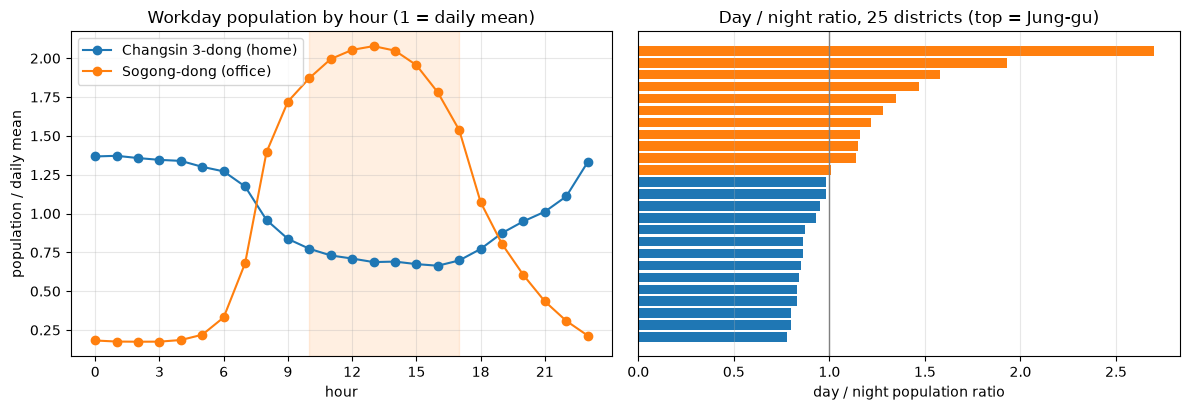

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
curve.plot(ax=ax1, marker="o")
ax1.axvspan(10, 17, color="tab:orange", alpha=.12)
ax1.set_title("Workday population by hour (1 = daily mean)")
ax1.set_xlabel("hour")
ax1.set_ylabel("population / daily mean")
ax1.set_xticks(range(0, 24, 3))

g = gu_ratio.sort_values("ratio")
ax2.barh(range(len(g)), g["ratio"], color=["tab:orange" if r >= 1 else "tab:blue" for r in g["ratio"]])
ax2.axvline(1, color="gray", lw=1)
ax2.set_yticks([])
ax2.set_title("Day / night ratio, 25 districts (top = Jung-gu)")
ax2.set_xlabel("day / night population ratio")
for a in (ax1, ax2):
    a.grid(alpha=.3)
plt.tight_layout()
plt.show()

> **확인 포인트** — 왼쪽 그림의 주황 띠(10~17시)에서 두 선이 반대로 움직입니다. 오른쪽 막대는 1 이상인 구(주황) 11개와 1보다 작은 구(파랑) 14개입니다. 11번째인 송파구(1.01)는 낮과 밤이 거의 같습니다.
> 막대 이름(구 이름)은 한글이라 그림에서 뺐습니다. 순서는 `gu_ratio` 표와 같습니다.

In [ ]:
assert (gu_ratio["ratio"] >= 1).sum() == 11

결과는 Parquet 으로 저장합니다. DuckDB 는 `COPY ... TO` 한 줄로 씁니다(3주차 14장). 열마다 형이 함께 저장되어 다음 사람이 형을 다시 바꿀 필요가 없습니다.

In [ ]:
duckdb.sql("COPY (SELECT * FROM ranked) TO 'data/dong_day_night_202606.parquet' (FORMAT parquet)")
duckdb.sql("COPY (SELECT * FROM gu_ratio) TO 'data/gu_day_night_202606.parquet' (FORMAT parquet)")

back = duckdb.sql("SELECT count(*), max(ratio) FROM 'data/dong_day_night_202606.parquet'").fetchall()[0]
print("다시 읽은 행:", back[0], "· 최대 비율:", back[1])
assert back == (424, 10.73)

다시 읽은 행: 424 · 최대 비율: 10.73


> **자주 겪는 오류** — 저장한 뒤에 `ranked` 를 고치면 Parquet 파일은 바뀌지 않습니다. 파일은 저장한 순간의 사진입니다. 기준(공휴일 · 시간대)을 바꿨으면 COPY 를 다시 실행하세요.

## 7단계 · 더 해 보기

- 낮 시간대를 10~17시 대신 12~14시(점심)로, 밤을 0~5시 대신 22~6시로 바꿔 보세요. 1위 · 꼴찌와 세 무리의 크기가 얼마나 달라지나요? 기준을 바꿔도 흔들리지 않는 결론만 보고서에 쓰세요.
- 일하는 날과 주말을 나눠 **주말 낮/밤 비율**을 내 보세요. 주말에 오히려 붐비는 동네(관광 · 쇼핑)가 따로 보입니다.
- 이름이 없던 9개 코드를 행정안전부 「행정기관(행정동) 및 관할구역 변경 내역」에서 찾아 이름표에 더해 보세요(P3 9단계와 같은 과제입니다).
- 원본 32개 열에는 성별 · 연령대별 인구가 있습니다. 서울 열린데이터광장에서 원본을 받아 「20~30대가 낮에 몰리는 동네」를 찾아보세요.